# Statistical Fidelity of Synthetic NEWS Data

This notebook compares `NEWSsample.csv` and `NEWSgenerated.csv` with respect to marginal distributions, pairwise dependence, and multivariate structure. The analysis assesses fidelity to the supplied reference sample; it does not establish physiological realism or validate NEWS scoring.

The reference sample informed data generation and therefore is not an independent validation dataset. Clinical provenance, observation identity, measurement units, and coding have not been independently verified. The six selected numerical fields are analysed as recorded, without assuming physical units.

The retained execution scans **1,000 reference records and 1,001,000 generated records**. Distributional analyses use bounded samples, as detailed below. A complete-file scan does not imply that every diagnostic uses all records.

| Analysis | Reference records | Generated records |
| --- | ---: | ---: |
| Schema, missingness, and numeric-conversion audit | 1,000 | 1,001,000 |
| Marginal distributions and record overlap | 1,000 | 20,000 |
| Pearson and Spearman correlations; bootstrap intervals; PCA and joint plots | 1,000 | 2,000 |
| Distance correlation | 350 | 350 |
| Maximum mean discrepancy | 500 | 500 |
| Source classification, per repetition | 1,000 | 1,000 |

To reproduce the analysis, place both CSV files beside the notebook, install the dependencies, and run all cells in order. Configuration parameters specify the input paths, fields, sampling limits, and random seed. Each execution writes CSV tables, PDF and PNG figures, input hashes, package versions, sampled row positions, and a summary report to a separate directory under `news_fidelity_results/`.

The saved outputs are retained from the supplied execution. Subsequent revisions concern explanatory text and presentation only; the numerical analyses and figures are unchanged.

## 1. Dependencies

The analysis requires NumPy, pandas, SciPy, scikit-learn, Matplotlib, and seaborn. The optional installation command is provided below. Package versions are recorded in the execution manifest.

In [1]:
# %pip install numpy pandas scipy scikit-learn matplotlib seaborn
import json, hashlib, platform, warnings, time
from pathlib import Path
from datetime import datetime
from itertools import combinations
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import rankdata, wasserstein_distance, ks_2samp
from scipy.spatial.distance import jensenshannon, pdist, cdist
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.decomposition import PCA
from IPython.display import display
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams.update({"pdf.fonttype":42, "ps.fonttype":42, "figure.dpi":110})


## 2. Configuration

`NUMERIC_COLUMNS` and `CATEGORICAL_COLUMNS` define the comparison fields. `GENERATED_RENAME` supports column-name alignment. `DOCUMENTED_RANGES` accepts externally documented bounds; an unspecified bound does not imply physiological validity. The current configuration leaves measurement semantics unverified.

`UNIT_COLUMN` may identify repeated observations from the same unit when a documented identifier is available. It is unset in the retained execution. Dependence estimates therefore describe records, with no established patient-level sampling interpretation.

`MODE="full"` selects the reporting configuration, including 1,000 bootstrap draws and five source-classification repetitions. Sampling caps remain active in this mode. `MODE="quick"` reduces computation for execution checks. Both modes use separate output directories.

In [2]:
REFERENCE_PATH = Path("NEWSsample.csv")
GENERATED_PATH = Path("NEWSgenerated.csv")
GENERATED_RENAME = {}  # e.g. {"generated_temperature": "temp_value"}
CSV_SEPARATOR = ","
CSV_ENCODING = "utf-8-sig"
MISSING_TOKENS = ["", "NA", "N/A", "NULL", "null", "NaN", "nan"]

NUMERIC_COLUMNS = ["pulse_value", "temp_value", "bp_sys_value",
                   "bp_dia_value", "resp_rate_value", "o2_sats_value"]
CATEGORICAL_COLUMNS = ["sex"]
SCORE_COLUMN = "ews_score"  # Ancillary score-distribution comparison.
UNIT_COLUMN = None         # Documented repeated-observation identifier, if available.
MEASUREMENT_SEMANTICS_CONFIRMED = False
REFERENCE_PROVENANCE = "Supplied reference example; clinical provenance not independently verified"
REFERENCE_USED_IN_GENERATION = True
DOCUMENTED_RANGES = {}     # e.g. {column: (documented_lower, documented_upper)}

MODE = "full"             # "quick" or "full"
SEED = 42
MAX_STORED_ROWS = 20000
CHUNK_SIZE = 50000
MAX_ASSOC_ROWS = 2000
MAX_DISTANCE_ROWS = 350
MAX_MMD_ROWS = 500
MAX_SOURCE_ROWS_PER_DATASET = 1000
BOOTSTRAPS = 1000 if MODE == "full" else 40
SOURCE_REPETITIONS = 5 if MODE == "full" else 1
N_TREES = 150 if MODE == "full" else 30
N_JOBS = 1  # Number of parallel workers.
assert MODE in {"quick", "full"}
assert len(NUMERIC_COLUMNS) >= 2 and len(set(NUMERIC_COLUMNS)) == len(NUMERIC_COLUMNS)
assert not set(NUMERIC_COLUMNS) & set(CATEGORICAL_COLUMNS)
OUT = Path("news_fidelity_results") / (MODE + "_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
OUT.mkdir(parents=True, exist_ok=False)
(OUT / "figures").mkdir()
(OUT / "tables").mkdir()
print("Output directory:", OUT.as_posix())


Output directory: news_fidelity_results/full_20261014_033244_356970


## 3. Data import and sampling

Each input is scanned in chunks to obtain complete-file row counts, missingness, and numeric-conversion diagnostics. Random-priority reservoir sampling retains a uniform subset of records without modifying the inputs. Subsequent distributional analyses use the retained records.

When a unit identifier is configured, dependence and multivariate analyses first select one random retained observation per observed unit. This operates within the reservoir and is not an equal-probability sample of units from the complete file. Input hashes, configuration, package versions, and retained row positions are exported for reproducibility.

In [3]:
def save_table(frame, name, index=False):
    frame.to_csv(OUT / "tables" / (name + ".csv"), index=index)
    return frame

def save_figure(fig, name):
    fig.savefig(OUT / "figures" / (name + ".pdf"), bbox_inches="tight", dpi=300)
    fig.savefig(OUT / "figures" / (name + ".png"), bbox_inches="tight", dpi=300)
    plt.show()
    plt.close(fig)

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(2**20), b""):
            h.update(block)
    return h.hexdigest()

def clean_headers(columns):
    cleaned = [str(c).strip() for c in columns]
    if len(cleaned) != len(set(cleaned)):
        raise ValueError("Duplicate column names after stripping spaces.")
    return cleaned

def scan_file(path, rename, seed):
    if not path.exists():
        raise FileNotFoundError(f"Place {path.name} beside the notebook or update its path: {path.resolve()}")
    raw_header = pd.read_csv(path, sep=CSV_SEPARATOR, encoding=CSV_ENCODING, nrows=0).columns
    header = clean_headers(raw_header)
    header = [rename.get(c, c) for c in header]
    if len(header) != len(set(header)):
        raise ValueError("Column renaming created duplicate names.")
    required = NUMERIC_COLUMNS + CATEGORICAL_COLUMNS + ([UNIT_COLUMN] if UNIT_COLUMN else [])
    absent = sorted(set(required) - set(header))
    if absent:
        raise ValueError(f"{path.name}: missing selected columns {absent}. Available: {header}")
    numeric_to_check = NUMERIC_COLUMNS + ([SCORE_COLUMN] if SCORE_COLUMN in header and SCORE_COLUMN not in NUMERIC_COLUMNS else [])
    missing_count = dict.fromkeys(header, 0)
    invalid_count = dict.fromkeys(numeric_to_check, 0)
    total = 0
    reservoir = None
    generator = np.random.default_rng(seed)
    reader = pd.read_csv(path, sep=CSV_SEPARATOR, encoding=CSV_ENCODING,
                         dtype=str, chunksize=CHUNK_SIZE, keep_default_na=False)
    for chunk in reader:
        chunk.columns = header
        for col in header:
            chunk[col] = chunk[col].str.strip().replace(MISSING_TOKENS, np.nan)
            missing_count[col] += int(chunk[col].isna().sum())
        for col in numeric_to_check:
            parsed = pd.to_numeric(chunk[col], errors="coerce")
            invalid_count[col] += int((chunk[col].notna() & (~np.isfinite(parsed))).sum())
        # Keep original zero-based CSV data-row positions separately.
        chunk["__source_position__"] = np.arange(total, total + len(chunk))
        chunk["__priority__"] = generator.random(len(chunk))
        total += len(chunk)
        reservoir = chunk if reservoir is None else pd.concat([reservoir, chunk], ignore_index=True)
        if len(reservoir) > MAX_STORED_ROWS:
            reservoir = reservoir.nsmallest(MAX_STORED_ROWS, "__priority__")
    if reservoir is None or total == 0:
        raise ValueError(f"{path.name} is empty.")
    reservoir = reservoir.drop(columns="__priority__").sort_values("__source_position__").reset_index(drop=True)
    audit = pd.DataFrame({"column":header, "file_rows":total,
                          "missing_count":[missing_count[c] for c in header],
                          "numeric_parse_or_nonfinite_count":[invalid_count.get(c, np.nan) for c in header]})
    audit["missing_fraction"] = audit["missing_count"] / total
    for col in numeric_to_check:
        reservoir[col] = pd.to_numeric(reservoir[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
    return reservoir, audit, total, header

reference, ref_audit, n_ref_full, ref_header = scan_file(REFERENCE_PATH, {}, SEED)
generated, gen_audit, n_gen_full, gen_header = scan_file(GENERATED_PATH, GENERATED_RENAME, SEED+1)
save_table(ref_audit, "reference_full_file_audit")
save_table(gen_audit, "generated_full_file_audit")
save_table(pd.DataFrame({"column": sorted(set(ref_header)|set(gen_header))}).assign(
    in_reference=lambda d:d.column.isin(ref_header), in_generated=lambda d:d.column.isin(gen_header)), "schema_alignment")
for name, data, total in [("Reference",reference,n_ref_full),("Generated",generated,n_gen_full)]:
    print(f"{name}: {total:,} file rows, {len(data):,} retained rows")
print("Reference-only columns:", sorted(set(ref_header)-set(gen_header)))
print("Generated-only columns:", sorted(set(gen_header)-set(ref_header)))
display(ref_audit[ref_audit.column.isin(NUMERIC_COLUMNS)])
print("Scope:", "Verified measurement mapping" if MEASUREMENT_SEMANTICS_CONFIRMED else "Encoded-column fidelity; clinical interpretation not established")

manifest = {"reference_path":str(REFERENCE_PATH.resolve()),"generated_path":str(GENERATED_PATH.resolve()),
    "reference_sha256":sha256(REFERENCE_PATH),"generated_sha256":sha256(GENERATED_PATH),
    "mode":MODE,"seed":SEED,"reference_rows":n_ref_full,"generated_rows":n_gen_full,
    "reference_retained":len(reference),"generated_retained":len(generated),
    "numeric_columns":NUMERIC_COLUMNS,"categorical_columns":CATEGORICAL_COLUMNS,
    "score_column":SCORE_COLUMN,"unit_column":UNIT_COLUMN,"generated_rename":GENERATED_RENAME,
    "measurement_semantics_confirmed":MEASUREMENT_SEMANTICS_CONFIRMED,
    "reference_provenance":REFERENCE_PROVENANCE,"reference_used_in_generation":REFERENCE_USED_IN_GENERATION,
    "documented_ranges":DOCUMENTED_RANGES,"bootstrap_draws":BOOTSTRAPS,
    "source_repetitions":SOURCE_REPETITIONS,"max_stored_rows":MAX_STORED_ROWS,
    "max_association_rows":MAX_ASSOC_ROWS,"max_distance_rows":MAX_DISTANCE_ROWS,
    "max_mmd_rows":MAX_MMD_ROWS,"max_source_rows":MAX_SOURCE_ROWS_PER_DATASET,
    "source_trees":N_TREES,"n_jobs":N_JOBS,"python":platform.python_version(),
    "versions":{p:version(p) for p in ["numpy","pandas","scipy","scikit-learn","matplotlib","seaborn"]}}
(OUT/"manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
for name,data in [("reference",reference),("generated",generated)]:
    save_table(data[["__source_position__"]], name+"_retained_positions")


Reference: 1,000 file rows, 1,000 retained rows
Generated: 1,001,000 file rows, 20,000 retained rows
Reference-only columns: []
Generated-only columns: []


,column,file_rows,missing_count,numeric_parse_or_nonfinite_count,missing_fraction
26,pulse_value,1000,0,0.0,0.0
28,temp_value,1000,0,0.0,0.0
30,bp_sys_value,1000,0,0.0,0.0
32,bp_dia_value,1000,0,0.0,0.0
34,resp_rate_value,1000,0,0.0,0.0
37,o2_sats_value,1000,0,0.0,0.0


Scope: Encoded-column fidelity; clinical interpretation not established


## 4. Descriptive quality and record overlap

Selected numerical fields are summarised using observed ranges, quantiles, and dispersion. Range checks are applied only where documented bounds are supplied. Constant reference fields are identified separately. NEWS scores are not recalculated because the measurement units, coding, and scoring specification have not been verified.

Record overlap is evaluated for the selected analysis fields and for common fields excluding names ending in `_id` and any configured unit identifier. Overlap and duplicate fractions refer to retained samples. Matching content alone does not identify its origin, and these diagnostics do not establish privacy or statistical independence.

In [4]:
rows=[]
for source,data in [("Reference",reference),("Generated",generated)]:
    for col in NUMERIC_COLUMNS:
        a=data[col].dropna()
        lo,hi=DOCUMENTED_RANGES.get(col,(None,None))
        rows.append({"source":source,"column":col,"n_valid":len(a),"n_unique":a.nunique(),
                     "min":a.min(),"max":a.max(),"mean":a.mean(),"sd":a.std(ddof=1),
                     "median":a.median(),"q25":a.quantile(.25),"q75":a.quantile(.75),
                     "documented_low":lo,"documented_high":hi,
                     "outside_documented_range_fraction":float(((a<lo)|(a>hi)).mean()) if lo is not None and hi is not None and len(a) else np.nan})
quality=save_table(pd.DataFrame(rows),"selected_column_quality")
display(quality)
constant_ref=[c for c in ref_header if reference[c].nunique(dropna=True)<=1]
print("Constant/empty columns in retained reference:",constant_ref)

def canonical_rows(data, columns):
    d=data[columns].copy()
    for c in columns:
        d[c]=d[c].astype("string").fillna("<MISSING>")
    return pd.util.hash_pandas_object(d,index=False)

selected=NUMERIC_COLUMNS+CATEGORICAL_COLUMNS
common_content=[c for c in ref_header if c in gen_header and not c.lower().endswith("_id") and c!=UNIT_COLUMN]
overlap_rows=[]
for definition,cols in [("selected_analysis_fields",selected),("common_non_id_content",common_content)]:
    rh=canonical_rows(reference,cols); gh=canonical_rows(generated,cols)
    overlap_rows.append({"definition":definition,"n_fields":len(cols),
        "reference_duplicate_fraction":rh.duplicated().mean(),
        "generated_duplicate_fraction":gh.duplicated().mean(),
        "generated_rows_matching_reference_fraction":gh.isin(set(rh)).mean()})
overlap=save_table(pd.DataFrame(overlap_rows),"retained_sample_overlap")
display(overlap)
# Reference diagnostics: empirical dependence only, not a claim of physiological validity.
preview_corr=reference[NUMERIC_COLUMNS].corr(method="spearman")
offdiag=preview_corr.to_numpy()[np.triu_indices(len(NUMERIC_COLUMNS),1)]
print("Reference maximum absolute off-diagonal Spearman:", np.nanmax(np.abs(offdiag)))
if not MEASUREMENT_SEMANTICS_CONFIRMED:
    print("Measurement units and coding are unverified; results describe recorded fields.")


,source,column,n_valid,n_unique,min,max,mean,sd,median,q25,q75,documented_low,documented_high,outside_documented_range_fraction
0,Reference,pulse_value,1000,100,0,99,40.02500,31.895293,38.0,8.0,66.0,None,None,NaN
1,Reference,temp_value,1000,100,0,99,39.23000,31.933319,35.0,7.0,68.0,None,None,NaN
2,Reference,bp_sys_value,1000,100,0,99,40.69400,31.986176,40.0,8.0,70.0,None,None,NaN
3,Reference,bp_dia_value,1000,100,0,99,40.48500,31.068811,39.0,10.0,67.0,None,None,NaN
4,Reference,resp_rate_value,1000,100,0,99,39.62300,32.315804,35.0,7.0,69.0,None,None,NaN
5,Reference,o2_sats_value,1000,100,0,99,40.23600,30.073788,36.0,9.0,67.0,None,None,NaN
6,Generated,pulse_value,20000,100,0,99,40.07800,32.030136,37.0,8.0,68.0,None,None,NaN
7,Generated,temp_value,20000,100,0,99,39.62180,31.791359,36.0,8.0,68.0,None,None,NaN
8,Generated,bp_sys_value,20000,100,0,99,40.16385,32.104665,37.0,8.0,68.0,None,None,NaN
9,Generated,bp_dia_value,20000,100,0,99,40.09240,31.997244,37.0,8.0,68.0,None,None,NaN


Constant/empty columns in retained reference: ['admission_date']


,definition,n_fields,reference_duplicate_fraction,generated_duplicate_fraction,generated_rows_matching_reference_fraction
0,selected_analysis_fields,7,0.0,0.02955,0.0042
1,common_non_id_content,52,0.0,0.00040,0.0008


Reference maximum absolute off-diagonal Spearman: 0.03780144538218428
Measurement units and coding are unverified; results describe recorded fields.


## 5. Numerical marginal distributions

Marginal fidelity is described by empirical cumulative distribution functions, Kolmogorov–Smirnov distances, Wasserstein-1 distances, and quantile differences. Wasserstein distances are reported in recorded units and normalised by the reference interquartile range, with reference standard deviation as a fallback. The normalised measure is undefined for a constant reference field.

Kolmogorov–Smirnov statistics are used as distributional distances, without hypothesis-test conclusions. Quantile differences are defined as generated minus reference. Plots retain the observed tails, and no retrospective acceptance thresholds are applied.

,column,reference_n,generated_n,ks_distance,wasserstein_native,reference_scale,wasserstein_normalized,generated_outside_reference_range_fraction,median_difference
0,pulse_value,1000,20000,0.02200,0.68670,58.0,0.01184,0.0,-1.0
1,temp_value,1000,20000,0.01710,0.60190,61.0,0.00987,0.0,1.0
2,bp_sys_value,1000,20000,0.02560,1.05635,62.0,0.01704,0.0,-3.0
3,bp_dia_value,1000,20000,0.02885,1.18780,57.0,0.02084,0.0,-2.0
4,resp_rate_value,1000,20000,0.01910,0.60265,62.0,0.00972,0.0,2.0
5,o2_sats_value,1000,20000,0.02905,1.00345,58.0,0.01730,0.0,1.0


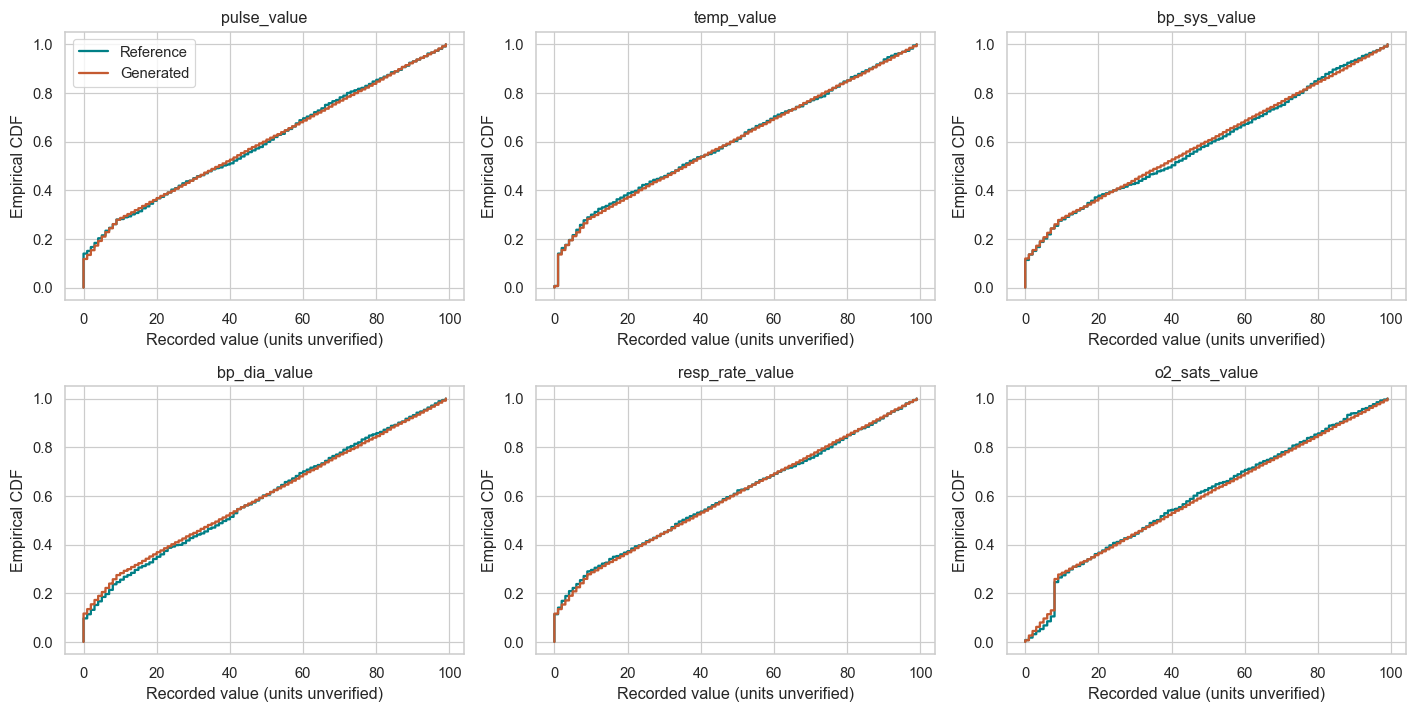

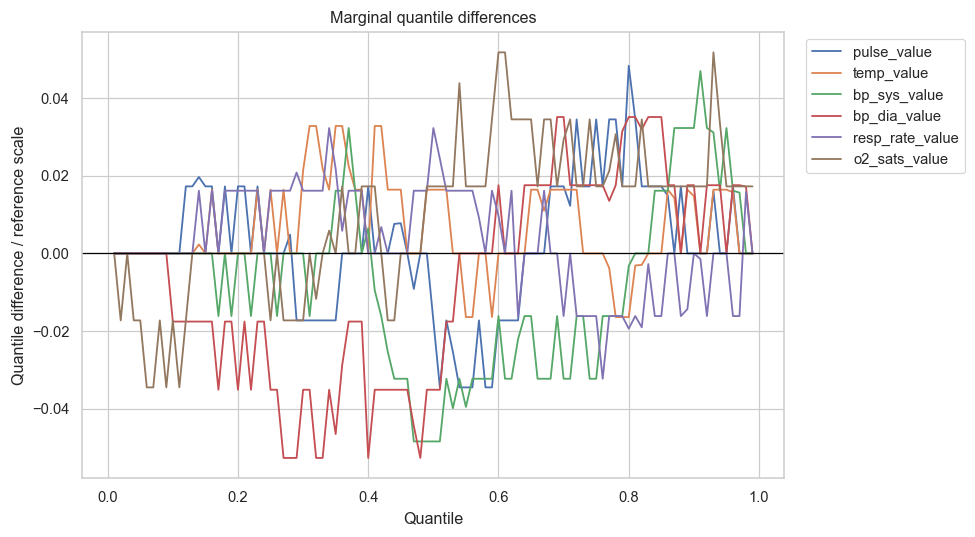

In [5]:
marginal_rows=[]
for c in NUMERIC_COLUMNS:
    a=reference[c].dropna().to_numpy(); b=generated[c].dropna().to_numpy()
    if min(len(a),len(b))<3:
        raise ValueError(f"Insufficient valid values in {c}.")
    scale=np.quantile(a,.75)-np.quantile(a,.25)
    if scale<=0: scale=np.std(a,ddof=1)
    w=wasserstein_distance(a,b)
    marginal_rows.append({"column":c,"reference_n":len(a),"generated_n":len(b),
        "ks_distance":ks_2samp(a,b,method="asymp").statistic,
        "wasserstein_native":w,"reference_scale":scale,
        "wasserstein_normalized":w/scale if scale>0 else np.nan,
        "generated_outside_reference_range_fraction":np.mean((b<a.min())|(b>a.max())),
        "median_difference":np.median(b)-np.median(a)})
marginals=save_table(pd.DataFrame(marginal_rows),"marginal_numeric_fidelity")
display(marginals.round(5))
fig,axes=plt.subplots(int(np.ceil(len(NUMERIC_COLUMNS)/3)),3,figsize=(13,3.3*np.ceil(len(NUMERIC_COLUMNS)/3)),squeeze=False)
for ax,c in zip(axes.flat,NUMERIC_COLUMNS):
    for data,color,label in [(reference,"#007F86","Reference"),(generated,"#C45A31","Generated")]:
        vals=np.sort(data[c].dropna().to_numpy()); ax.step(vals,np.arange(1,len(vals)+1)/len(vals),where="post",color=color,label=label,lw=1.5)
    ax.set(title=c,xlabel="Recorded value (units unverified)" if not MEASUREMENT_SEMANTICS_CONFIRMED else "Value",ylabel="Empirical CDF")
for ax in list(axes.flat)[len(NUMERIC_COLUMNS):]:ax.set_visible(False)
axes.flat[0].legend(); fig.tight_layout(); save_figure(fig,"01_marginal_ecdfs")
q=np.linspace(.01,.99,99)
fig,ax=plt.subplots(figsize=(9,5))
for c in NUMERIC_COLUMNS:
    a=reference[c].dropna(); b=generated[c].dropna()
    scale=marginals.set_index("column").loc[c,"reference_scale"]
    if scale>0:ax.plot(q,(np.quantile(b,q)-np.quantile(a,q))/scale,label=c)
ax.axhline(0,color="black",lw=.8); ax.set(xlabel="Quantile",ylabel="Quantile difference / reference scale",title="Marginal quantile differences")
ax.legend(bbox_to_anchor=(1.02,1),loc="upper left"); fig.tight_layout(); save_figure(fig,"02_quantile_difference")


## 6. Categorical and recorded score distributions

Categorical distributions are compared using total variation distance and base-2 Jensen–Shannon divergence, both bounded by zero and one. Missing values are represented as a separate category. The recorded `ews_score` distribution is assessed separately from the numerical fields; distributional agreement does not establish scoring-rule correctness.

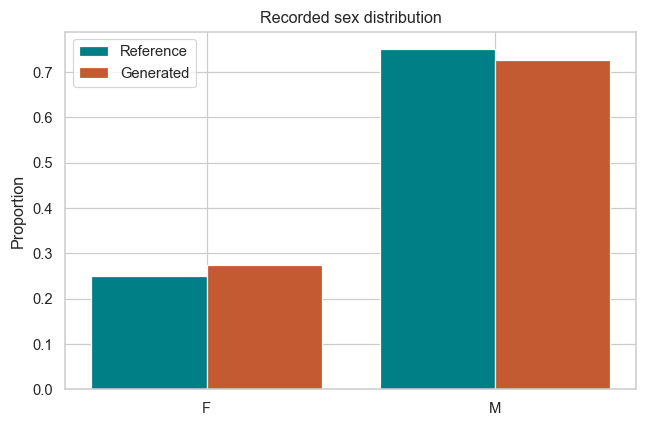

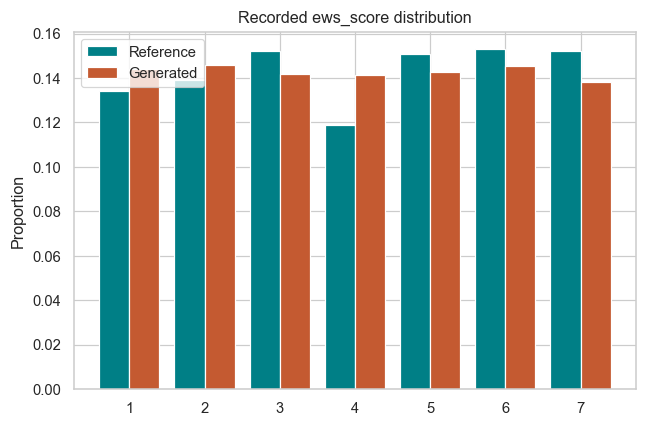

,column,n_categories,total_variation,js_divergence_bits
0,sex,2,0.02470,0.000570
1,ews_score,7,0.03955,0.001406


NEWS scoring-rule consistency was not assessed.


In [6]:
category_rows=[]
cat_columns=CATEGORICAL_COLUMNS+([SCORE_COLUMN] if SCORE_COLUMN in reference and SCORE_COLUMN in generated and SCORE_COLUMN not in CATEGORICAL_COLUMNS else [])
for c in cat_columns:
    a=reference[c].astype("string").fillna("<MISSING>")
    b=generated[c].astype("string").fillna("<MISSING>")
    levels=sorted(set(a)|set(b))
    pa=a.value_counts(normalize=True).reindex(levels,fill_value=0)
    pb=b.value_counts(normalize=True).reindex(levels,fill_value=0)
    category_rows.append({"column":c,"n_categories":len(levels),"total_variation":.5*np.abs(pa-pb).sum(),
                          "js_divergence_bits":float(jensenshannon(pa,pb,base=2)**2)})
    save_table(pd.DataFrame({"category":levels,"reference_probability":pa.values,"generated_probability":pb.values}),"category_"+c)
    if len(levels)<=30:
        fig,ax=plt.subplots(figsize=(max(6,len(levels)*.45),4))
        x=np.arange(len(levels)); ax.bar(x-.2,pa,width=.4,label="Reference",color="#007F86"); ax.bar(x+.2,pb,width=.4,label="Generated",color="#C45A31")
        ax.set_xticks(x,levels); ax.set(ylabel="Proportion",title=f"Recorded {c} distribution"); ax.legend();fig.tight_layout();save_figure(fig,"03_category_"+c)
categories=save_table(pd.DataFrame(category_rows),"categorical_fidelity")
display(categories)
print("NEWS scoring-rule consistency was not assessed.")


## 7. Pairwise dependence

Pearson and Spearman correlations are calculated from complete cases across the selected numerical fields. Each source uses a common set of observations for all pairs. Incomplete observations and constant fields are reported, and no imputation is applied to correlation estimates.

The association sample is independently capped for each source. Summary differences use unique off-diagonal pairs and are defined as generated minus reference. Association-sample row positions are exported. With no verified unit identifier, within-person dependence cannot be assessed.

Complete cases (reference/generated): 1000 20000
Excluded incomplete units: 0 0
Excluded constant columns: []


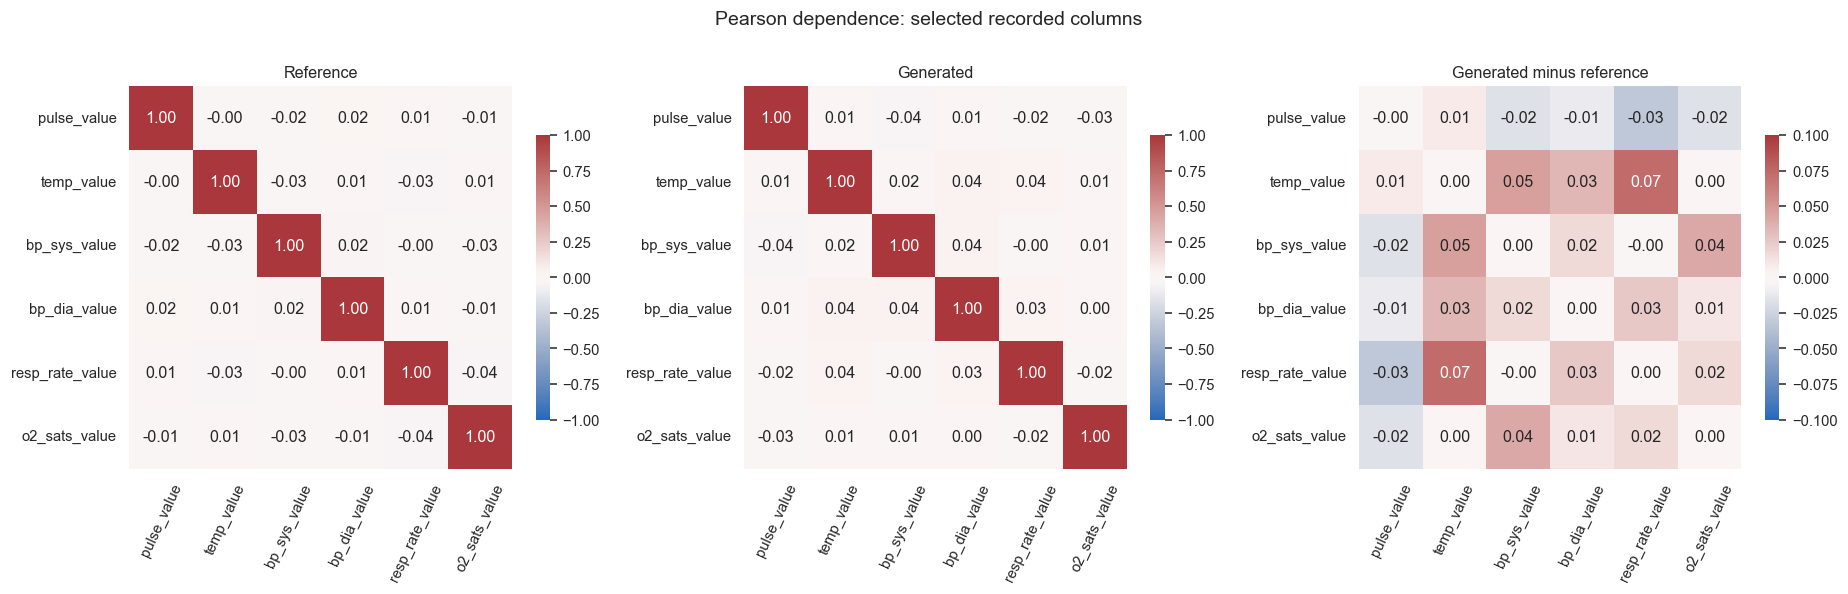

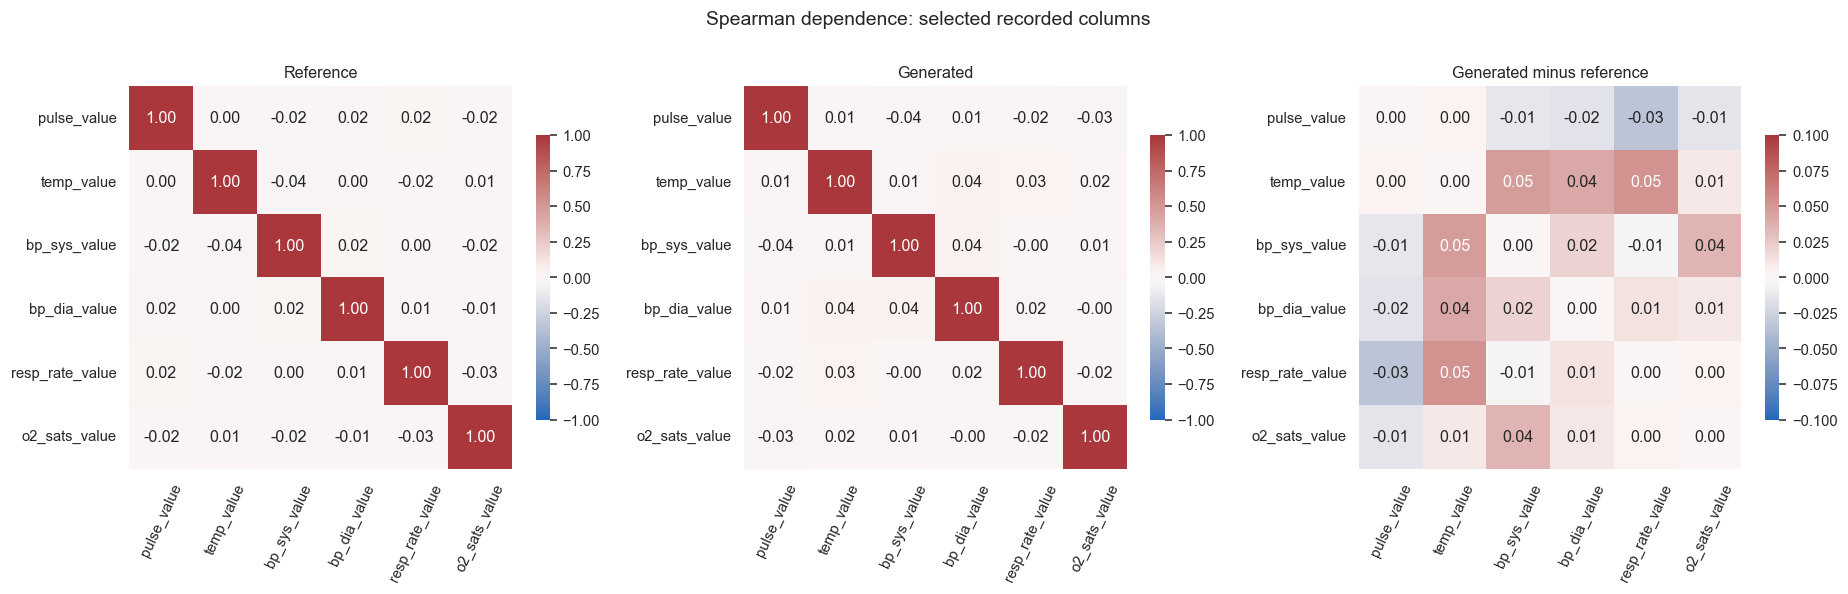

,method,n_reference,n_generated,mean_absolute_pair_difference,root_mean_square_pair_difference,max_absolute_pair_difference,reference_max_absolute_pair_correlation
0,pearson,1000,2000,0.023393,0.029890,0.073084,0.035645
1,spearman,1000,2000,0.021351,0.026554,0.052510,0.037801


In [7]:
def select_units(data,seed):
    if UNIT_COLUMN is None:return data.copy()
    if data[UNIT_COLUMN].isna().any():raise ValueError("Missing unit identifiers must be resolved first.")
    return data.sample(frac=1,random_state=seed).drop_duplicates(UNIT_COLUMN).copy()
ref_units=select_units(reference,SEED+2)
gen_units=select_units(generated,SEED+3)
ref_complete=ref_units.dropna(subset=NUMERIC_COLUMNS)
gen_complete=gen_units.dropna(subset=NUMERIC_COLUMNS)
print("Complete cases (reference/generated):",len(ref_complete),len(gen_complete))
print("Excluded incomplete units:",len(ref_units)-len(ref_complete),len(gen_units)-len(gen_complete))
if min(len(ref_complete),len(gen_complete))<20:raise ValueError("Too few complete cases for dependence analysis.")
ref_assoc=ref_complete.sample(n=min(MAX_ASSOC_ROWS,len(ref_complete)),random_state=SEED+4)
gen_assoc=gen_complete.sample(n=min(MAX_ASSOC_ROWS,len(gen_complete)),random_state=SEED+5)
active=[c for c in NUMERIC_COLUMNS if ref_assoc[c].nunique()>1 and gen_assoc[c].nunique()>1]
print("Excluded constant columns:",sorted(set(NUMERIC_COLUMNS)-set(active)))
if len(active)<2:raise ValueError("At least two nonconstant columns in both sources are required.")
save_table(ref_assoc[["__source_position__"]],"reference_association_positions")
save_table(gen_assoc[["__source_position__"]],"generated_association_positions")
A=ref_assoc[active].to_numpy(float); B=gen_assoc[active].to_numpy(float)
PAIRS=list(combinations(range(len(active)),2))
TRIU=np.triu_indices(len(active),1)

def correlation_matrix(array,method):
    z=rankdata(array,axis=0,method="average") if method=="spearman" else array
    with np.errstate(invalid="ignore",divide="ignore"):
        return np.corrcoef(z,rowvar=False)

correlation_summary=[]
correlations={}
for method in ["pearson","spearman"]:
    cr=correlation_matrix(A,method); cg=correlation_matrix(B,method); delta=cg-cr
    correlations[method]=(cr,cg)
    for name,mat in [("reference",cr),("generated",cg),("difference",delta)]:
        save_table(pd.DataFrame(mat,index=active,columns=active),method+"_"+name,index=True)
    correlation_summary.append({"method":method,"n_reference":len(A),"n_generated":len(B),
        "mean_absolute_pair_difference":np.nanmean(np.abs(delta[TRIU])),
        "root_mean_square_pair_difference":np.sqrt(np.nanmean(delta[TRIU]**2)),
        "max_absolute_pair_difference":np.nanmax(np.abs(delta[TRIU])),
        "reference_max_absolute_pair_correlation":np.nanmax(np.abs(cr[TRIU]))})
    fig,axes=plt.subplots(1,3,figsize=(17,5))
    for ax,mat,title,limit in zip(axes,[cr,cg,delta],["Reference","Generated","Generated minus reference"],[1,1,max(.1,float(np.nanmax(abs(delta))))]):
        sns.heatmap(pd.DataFrame(mat,index=active,columns=active),ax=ax,cmap="vlag",center=0,vmin=-limit,vmax=limit,annot=True,fmt=".2f",square=True,cbar_kws={"shrink":.7})
        ax.set_title(title);ax.tick_params(axis="x",rotation=65)
    fig.suptitle(method.capitalize()+" dependence: selected recorded columns",y=1.02);fig.tight_layout();save_figure(fig,"04_"+method+"_dependence")
correlation_summary=save_table(pd.DataFrame(correlation_summary),"dependence_matrix_summary")
display(correlation_summary)


## 8. Conditional bootstrap intervals

Rows are resampled independently within each observed association sample, preserving all fields jointly. Spearman ranks, including ties, are recomputed in each draw. Percentile 95% intervals are calculated for each source correlation and for generated-minus-reference differences.

These intervals are pointwise and conditional on the observed samples. They quantify empirical resampling variability but do not account for generator-fitting uncertainty, reference reuse during generation, or unverified dependence between records. They are neither simultaneous intervals nor equivalence tests; inclusion of zero does not establish equivalence.

Bootstrap 200/1000
Bootstrap 400/1000
Bootstrap 600/1000
Bootstrap 800/1000
Bootstrap 1000/1000


,feature_1,feature_2,reference_rho,reference_lower,reference_upper,generated_rho,generated_lower,generated_upper,delta_rho,delta_lower,delta_upper,valid_difference_draws
0,pulse_value,temp_value,0.0013,-0.0627,0.0628,0.0051,-0.0410,0.0462,0.0038,-0.0686,0.0794,1000
1,pulse_value,bp_sys_value,-0.0233,-0.0825,0.0427,-0.0372,-0.0797,0.0074,-0.0138,-0.0892,0.0593,1000
2,pulse_value,bp_dia_value,0.0240,-0.0383,0.0840,0.0088,-0.0334,0.0513,-0.0152,-0.0928,0.0594,1000
3,pulse_value,resp_rate_value,0.0186,-0.0441,0.0845,-0.0151,-0.0582,0.0314,-0.0336,-0.1070,0.0403,1000
4,pulse_value,o2_sats_value,-0.0175,-0.0814,0.0438,-0.0320,-0.0762,0.0129,-0.0145,-0.0873,0.0611,1000
5,temp_value,bp_sys_value,-0.0378,-0.0996,0.0251,0.0097,-0.0314,0.0540,0.0475,-0.0329,0.1246,1000
6,temp_value,bp_dia_value,0.0029,-0.0557,0.0675,0.0440,0.0030,0.0894,0.0412,-0.0376,0.1174,1000
7,temp_value,resp_rate_value,-0.0175,-0.0774,0.0437,0.0350,-0.0068,0.0747,0.0525,-0.0159,0.1269,1000
8,temp_value,o2_sats_value,0.0051,-0.0592,0.0649,0.0151,-0.0280,0.0564,0.0101,-0.0643,0.0943,1000
9,bp_sys_value,bp_dia_value,0.0194,-0.0427,0.0819,0.0400,-0.0043,0.0846,0.0206,-0.0570,0.0983,1000


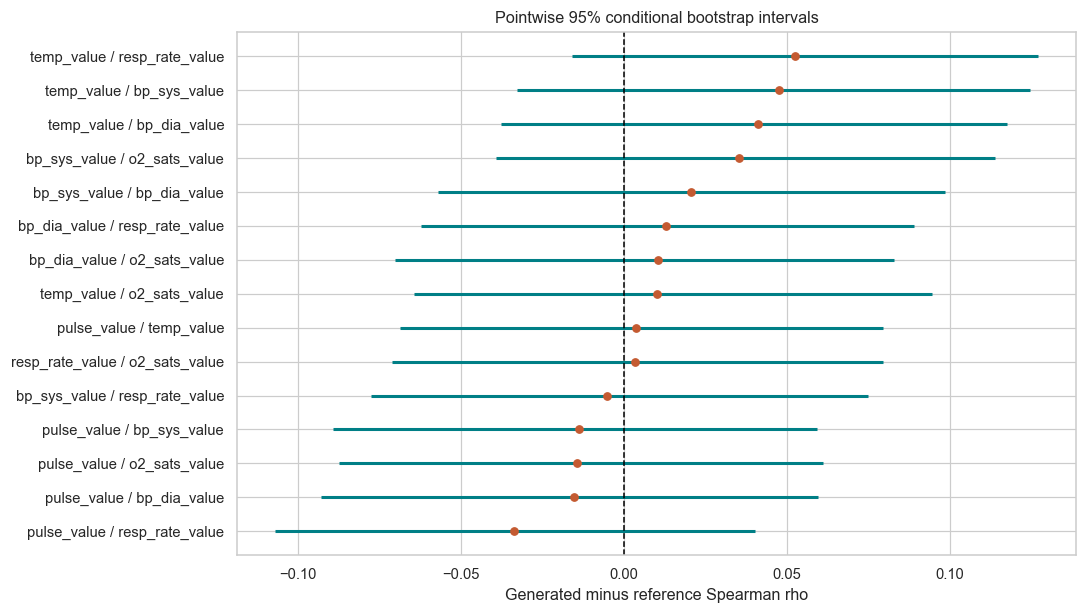

In [8]:
rng=np.random.default_rng(SEED+20)
r_boot=np.full((BOOTSTRAPS,len(PAIRS)),np.nan)
g_boot=np.full_like(r_boot,np.nan)
for k in range(BOOTSTRAPS):
    r_boot[k]=correlation_matrix(A[rng.integers(0,len(A),len(A))],"spearman")[TRIU]
    g_boot[k]=correlation_matrix(B[rng.integers(0,len(B),len(B))],"spearman")[TRIU]
    if (k+1)%max(1,BOOTSTRAPS//5)==0:print(f"Bootstrap {k+1}/{BOOTSTRAPS}",flush=True)
cr,cg=correlations["spearman"]
ci_rows=[]
for k,(i,j) in enumerate(PAIRS):
    rr=r_boot[:,k];gg=g_boot[:,k];dd=gg-rr
    valid=np.isfinite(dd)
    if valid.sum()<.9*BOOTSTRAPS:
        warnings.warn(f"Unstable bootstrap for {active[i]} / {active[j]}; inspect valid draw count.")
    def interval(v):
        v=v[np.isfinite(v)]
        return np.quantile(v,[.025,.975]) if len(v) else [np.nan,np.nan]
    rl,rh=interval(rr);gl,gh=interval(gg);dl,dh=interval(dd)
    ci_rows.append({"feature_1":active[i],"feature_2":active[j],"reference_rho":cr[i,j],
        "reference_lower":rl,"reference_upper":rh,"generated_rho":cg[i,j],
        "generated_lower":gl,"generated_upper":gh,"delta_rho":cg[i,j]-cr[i,j],
        "delta_lower":dl,"delta_upper":dh,"valid_difference_draws":int(valid.sum())})
ci=save_table(pd.DataFrame(ci_rows),"spearman_pointwise_bootstrap_intervals")
display(ci.round(4))
plot_ci=ci.sort_values("delta_rho").reset_index(drop=True)
fig,ax=plt.subplots(figsize=(10,max(5,.38*len(plot_ci))))
y=np.arange(len(plot_ci));ax.hlines(y,plot_ci.delta_lower,plot_ci.delta_upper,color="#007F86",lw=2)
ax.scatter(plot_ci.delta_rho,y,color="#C45A31",s=24,zorder=3)
ax.axvline(0,color="black",ls="--",lw=1)
ax.set_yticks(y,plot_ci.feature_1+" / "+plot_ci.feature_2)
ax.set(xlabel="Generated minus reference Spearman rho",title="Pointwise 95% conditional bootstrap intervals")
fig.tight_layout();save_figure(fig,"05_correlation_difference_intervals")


## 9. Nonlinear dependence and multivariate discrepancy

Distance correlation is calculated using the nonnegative, biased empirical estimator and equal sample sizes. Its finite-sample value under independence need not be zero. The results are descriptive; no independence-test p-values are reported.

Maximum mean discrepancy (MMD) uses a Gaussian kernel after scaling numerical fields by reference-sample medians and interquartile ranges. The kernel bandwidth squared is the median positive pooled squared distance. The biased MMD-squared statistic is displayed alongside a pooled random-allocation distribution. Because the reference informed generation, this comparison is treated as a diagnostic rather than an independent-validation hypothesis test.

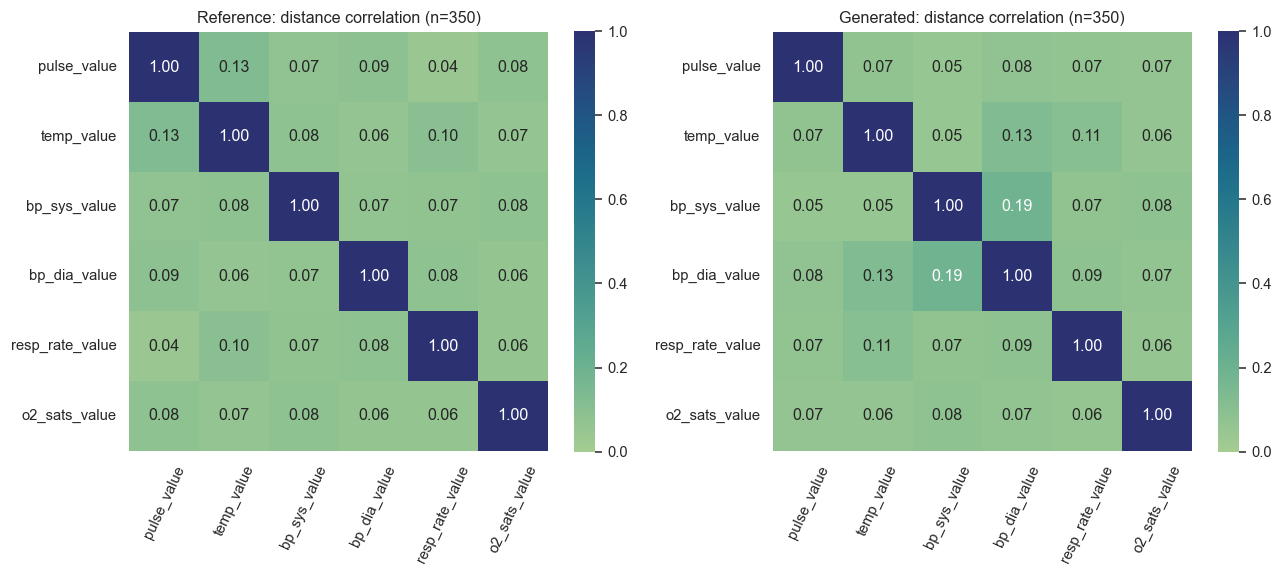

,n_each,biased_mmd_squared,kernel_bandwidth_squared,pooled_random_allocation_median,pooled_random_allocation_q95,inferential_p_value_reported
0,500,0.000787,3.237639,0.00144,0.00288,False


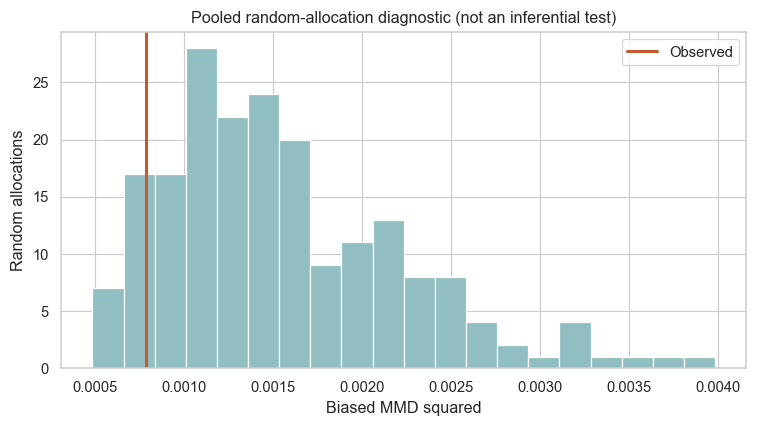

In [9]:
def centered_distances(v):
    d=np.abs(v[:,None]-v[None,:])
    return d-d.mean(axis=0,keepdims=True)-d.mean(axis=1,keepdims=True)+d.mean()

def distance_corr_matrix(arr):
    centered=[centered_distances(arr[:,j]) for j in range(arr.shape[1])]
    norms=np.array([np.mean(d*d) for d in centered])
    m=np.eye(arr.shape[1])
    for i,j in combinations(range(arr.shape[1]),2):
        denominator=np.sqrt(norms[i]*norms[j])
        value=np.sqrt(max(0,float(np.mean(centered[i]*centered[j])))/denominator) if denominator>0 else np.nan
        m[i,j]=m[j,i]=value
    return m

rng=np.random.default_rng(SEED+30)
n=min(MAX_DISTANCE_ROWS,len(A),len(B))
DA=A[rng.choice(len(A),n,replace=False)]; DB=B[rng.choice(len(B),n,replace=False)]
dcr=distance_corr_matrix(DA); dcg=distance_corr_matrix(DB)
for name,mat in [("reference",dcr),("generated",dcg)]:
    save_table(pd.DataFrame(mat,index=active,columns=active),"distance_correlation_"+name,index=True)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,mat,title in zip(axes,[dcr,dcg],["Reference","Generated"]):
    sns.heatmap(pd.DataFrame(mat,index=active,columns=active),ax=ax,vmin=0,vmax=1,cmap="crest",annot=True,fmt=".2f",square=True)
    ax.set_title(f"{title}: distance correlation (n={n})");ax.tick_params(axis="x",rotation=65)
fig.tight_layout();save_figure(fig,"06_nonlinear_dependence")

n=min(MAX_MMD_ROWS,len(A),len(B))
MA=A[rng.choice(len(A),n,replace=False)];MB=B[rng.choice(len(B),n,replace=False)]
center=np.median(MA,axis=0);scale=np.quantile(MA,.75,axis=0)-np.quantile(MA,.25,axis=0)
scale=np.where(scale>0,scale,1)
Z=np.vstack([(MA-center)/scale,(MB-center)/scale])
d2=cdist(Z,Z,metric="sqeuclidean");positive=d2[np.triu_indices(len(Z),1)];positive=positive[positive>0]
bandwidth=float(np.median(positive)) if len(positive) else 1.0
K=np.exp(-d2/(2*bandwidth))

def mmd_stat(kernel,idx_a,idx_b):
    return float(kernel[np.ix_(idx_a,idx_a)].mean()+kernel[np.ix_(idx_b,idx_b)].mean()-2*kernel[np.ix_(idx_a,idx_b)].mean())
observed_mmd=max(0.,mmd_stat(K,np.arange(n),np.arange(n,2*n)))
null=[]
for _ in range(199 if MODE=="full" else 39):
    order=rng.permutation(2*n);null.append(max(0.,mmd_stat(K,order[:n],order[n:])))
mmd_summary=save_table(pd.DataFrame([{"n_each":n,"biased_mmd_squared":observed_mmd,
    "kernel_bandwidth_squared":bandwidth,"pooled_random_allocation_median":np.median(null),
    "pooled_random_allocation_q95":np.quantile(null,.95),"inferential_p_value_reported":False}]),"mmd_diagnostic")
display(mmd_summary)
fig,ax=plt.subplots(figsize=(7,4));ax.hist(null,bins=20,color="#91BFC1",edgecolor="white")
ax.axvline(observed_mmd,color="#C45A31",lw=2,label="Observed")
ax.set(xlabel="Biased MMD squared",ylabel="Random allocations",title="Pooled random-allocation diagnostic (not an inferential test)")
ax.legend();fig.tight_layout();save_figure(fig,"07_mmd_diagnostic")


## 10. Source classification

Logistic regression and random forest classifiers distinguish reference records (0) from generated records (1), using selected numerical and categorical fields. Each repetition uses equal source sample sizes and five-fold stratified group cross-validation. Identical feature vectors are assigned to the same fold across sources. Preprocessing is fitted within each training fold.

Out-of-fold ROC AUC measures source separation under this design. Values near 0.5 indicate limited discrimination by the evaluated models and do not establish distributional equivalence. Values below 0.5 are retained without post hoc reversal. No model is selected or tuned using these AUCs.

The reference records may recur across repetitions. Reported standard deviations and ranges describe variability across sampled records and fold assignments, not population confidence intervals. These classifiers predict data source, not clinical outcomes or infrastructure workload.

Source diagnostic 1/5, Logistic regression: OOF AUC=0.4876
Source diagnostic 1/5, Random forest: OOF AUC=0.5112
Source diagnostic 2/5, Logistic regression: OOF AUC=0.4873
Source diagnostic 2/5, Random forest: OOF AUC=0.5240
Source diagnostic 3/5, Logistic regression: OOF AUC=0.4819
Source diagnostic 3/5, Random forest: OOF AUC=0.5134
Source diagnostic 4/5, Logistic regression: OOF AUC=0.4969
Source diagnostic 4/5, Random forest: OOF AUC=0.4760
Source diagnostic 5/5, Logistic regression: OOF AUC=0.4959
Source diagnostic 5/5, Random forest: OOF AUC=0.4992


,mean,std,min,max
classifier,,,,
Logistic regression,0.489905,0.006338,0.481900,0.496873
Random forest,0.504743,0.018342,0.475965,0.523962


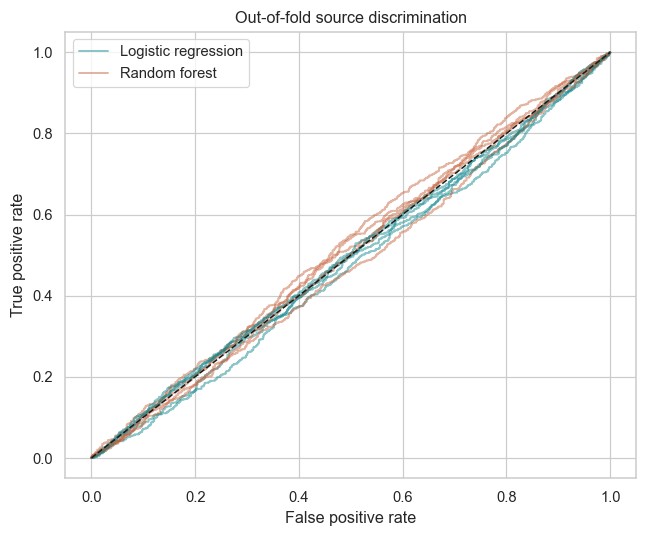

In [10]:
source_features=active+CATEGORICAL_COLUMNS
numeric_pipeline=Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())])
transformers=[("numeric",numeric_pipeline,active)]
if CATEGORICAL_COLUMNS:
    categorical_pipeline=Pipeline([("impute",SimpleImputer(strategy="most_frequent")),
                                   ("encode",OneHotEncoder(handle_unknown="ignore"))])
    transformers.append(("categorical",categorical_pipeline,CATEGORICAL_COLUMNS))
preprocessor=ColumnTransformer(transformers)
source_models={
    "Logistic regression":Pipeline([("preprocess",clone(preprocessor)),("classifier",LogisticRegression(max_iter=2000,random_state=SEED))]),
    "Random forest":Pipeline([("preprocess",clone(preprocessor)),("classifier",RandomForestClassifier(n_estimators=N_TREES,min_samples_leaf=5,max_features="sqrt",n_jobs=N_JOBS,random_state=SEED))])}
auc_rows=[];roc_rows=[]
for repeat in range(SOURCE_REPETITIONS):
    n=min(MAX_SOURCE_ROWS_PER_DATASET,len(ref_units),len(gen_units))
    if n<25:raise ValueError("Insufficient rows for source classification.")
    r=ref_units.sample(n=n,random_state=SEED+100+repeat)
    g=gen_units.sample(n=n,random_state=SEED+200+repeat)
    xx=pd.concat([r[source_features],g[source_features]],ignore_index=True)
    for c in CATEGORICAL_COLUMNS:xx[c]=xx[c].astype(object).where(xx[c].notna(),np.nan)
    yy=np.r_[np.zeros(n,dtype=int),np.ones(n,dtype=int)]
    duplicate_group=canonical_rows(xx,source_features).to_numpy()
    splitter=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+repeat)
    folds=list(splitter.split(xx,yy,groups=duplicate_group))
    for train,test in folds:
        if len(np.unique(yy[train]))<2 or len(np.unique(yy[test]))<2:
            raise ValueError("Source CV fold has only one class; duplicate concentration prevents this CV design.")
    for name,estimator in source_models.items():
        pred=np.full(len(xx),np.nan)
        for train,test in folds:
            fitted=clone(estimator).fit(xx.iloc[train],yy[train])
            pred[test]=fitted.predict_proba(xx.iloc[test])[:,1]
        auc=roc_auc_score(yy,pred)
        auc_rows.append({"repetition":repeat+1,"classifier":name,"n_each":n,"oof_auc":auc})
        fpr,tpr,_=roc_curve(yy,pred)
        roc_rows.append((name,repeat,fpr,tpr))
        save_table(pd.DataFrame({"source":yy,"source_row":np.r_[r.__source_position__.to_numpy(),g.__source_position__.to_numpy()],"oof_probability_generated":pred}),f"source_predictions_{name.replace(' ','_')}_{repeat+1}")
        print(f"Source diagnostic {repeat+1}/{SOURCE_REPETITIONS}, {name}: OOF AUC={auc:.4f}",flush=True)
auc_results=save_table(pd.DataFrame(auc_rows),"source_classifier_auc")
auc_summary=auc_results.groupby("classifier").oof_auc.agg(["mean","std","min","max"])
save_table(auc_summary,"source_classifier_auc_summary",index=True)
display(auc_summary)
fig,ax=plt.subplots(figsize=(6,5));colors={"Logistic regression":"#007F86","Random forest":"#C45A31"}
for name,repeat,fpr,tpr in roc_rows:ax.plot(fpr,tpr,color=colors[name],alpha=.45,lw=1.3,label=name if repeat==0 else None)
ax.plot([0,1],[0,1],"k--",lw=1);ax.set(xlabel="False positive rate",ylabel="True positive rate",title="Out-of-fold source discrimination")
ax.legend();fig.tight_layout();save_figure(fig,"08_source_discrimination")


## 11. Multivariate visualisation

PCA is fitted to standardised reference observations and applied to both sources. Two-component overlap provides an exploratory view rather than evidence of full-distribution equivalence.

Joint hexbin plots show the three pairs with the largest absolute reference Spearman correlations. Pair selection is exploratory and does not imply clinical importance. Panels display raw counts with individual colour scales and unequal source sample sizes; colour intensity is not directly comparable across sources. Axis labels retain the recorded field names.

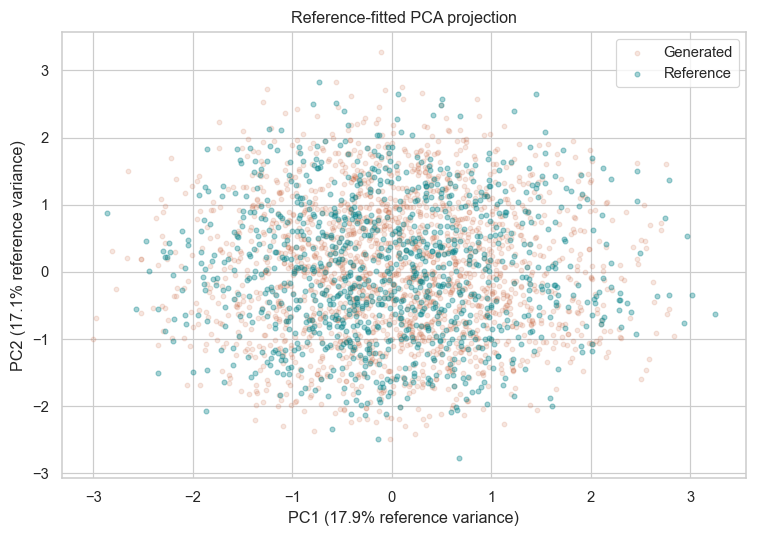

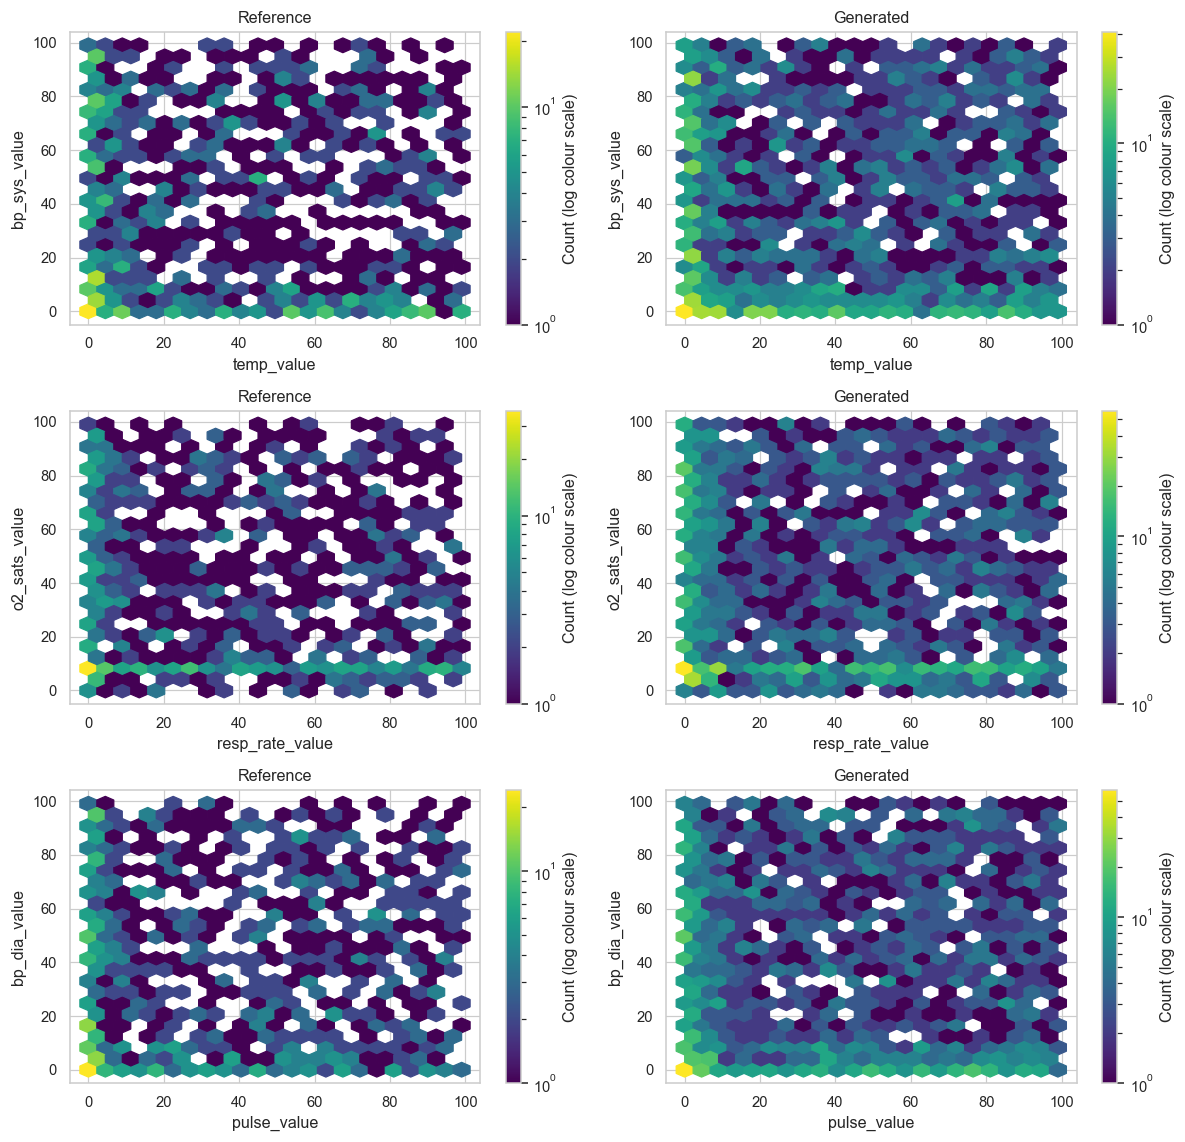

In [11]:
scaler=StandardScaler().fit(A)
Ar=scaler.transform(A);Br=scaler.transform(B)
pca=PCA(n_components=2).fit(Ar)
pr=pca.transform(Ar);pg=pca.transform(Br)
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(pg[:,0],pg[:,1],s=9,alpha=.15,color="#C45A31",label="Generated")
ax.scatter(pr[:,0],pr[:,1],s=10,alpha=.35,color="#007F86",label="Reference")
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} reference variance)",ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} reference variance)",title="Reference-fitted PCA projection")
ax.legend();fig.tight_layout();save_figure(fig,"09_pca_projection")
strongest=np.argsort(-np.abs(correlations["spearman"][0][TRIU]))[:min(3,len(PAIRS))]
fig,axes=plt.subplots(len(strongest),2,figsize=(11,3.5*len(strongest)),squeeze=False)
for row,k in enumerate(strongest):
    i,j=PAIRS[k]
    low=np.minimum(A[:,[i,j]].min(axis=0),B[:,[i,j]].min(axis=0));high=np.maximum(A[:,[i,j]].max(axis=0),B[:,[i,j]].max(axis=0))
    extent=(low[0],high[0],low[1],high[1])
    for ax,data,name in zip(axes[row],[A,B],["Reference","Generated"]):
        im=ax.hexbin(data[:,i],data[:,j],gridsize=22,mincnt=1,extent=extent,cmap="viridis",bins="log")
        ax.set(xlabel=active[i],ylabel=active[j],title=name);fig.colorbar(im,ax=ax,label="Count (log colour scale)")
fig.tight_layout();save_figure(fig,"10_joint_distributions")


## 12. Analysis summary

The following cell exports the observed dependence summaries, multivariate diagnostics, and interpretation limits to `interpretation_report.md`. Conclusions concern fidelity to the supplied reference under the selected analyses. Clinical realism, NEWS scoring correctness, and independent external validation remain outside the evidential scope of this comparison.

In [12]:
spear=correlation_summary.set_index("method").loc["spearman"]
report=f"""# Statistical Fidelity of Synthetic NEWS Data

Analysis mode: {MODE}. Reference file rows: {n_ref_full:,}; generated file rows: {n_gen_full:,}.
Retained samples: {len(reference):,} reference and {len(generated):,} generated rows.
Selected numeric fields: {', '.join(NUMERIC_COLUMNS)}.
Measurement semantics verified: {MEASUREMENT_SEMANTICS_CONFIRMED}.
Reference provenance: {REFERENCE_PROVENANCE}.
Reference used in generation: {REFERENCE_USED_IN_GENERATION}.

## Pairwise dependence
Complete-case dependence analysis used {len(A):,} reference and {len(B):,} generated observations.
The mean absolute difference between pairwise Spearman correlations was {spear['mean_absolute_pair_difference']:.4f};
the largest absolute difference was {spear['max_absolute_pair_difference']:.4f}.
The largest absolute pairwise Spearman correlation in the reference was {spear['reference_max_absolute_pair_correlation']:.4f}.
Pair-specific point estimates and pointwise conditional 95% bootstrap intervals are provided in spearman_pointwise_bootstrap_intervals.csv.
These intervals describe empirical resampling variability and do not establish independent clinical validation or equivalence.

## Marginals and multivariate diagnostics
Numeric marginal effect sizes appear in marginal_numeric_fidelity.csv; categorical differences appear in categorical_fidelity.csv.
The Gaussian-kernel biased MMD-squared statistic was {observed_mmd:.6f} using {int(mmd_summary.iloc[0]['n_each'])} rows per source.
The pooled random-allocation distribution is descriptive; no inferential p-value was reported.
Source-classifier OOF AUC summaries (repetition SD/range, not population confidence intervals):
{auc_summary.to_string()}

## Interpretation limits
The analysis assesses statistical fidelity to a reference sample that informed generation.
The weak reference correlations limit conclusions about preservation of physiological dependence.
Clinical provenance, observation identity, measurement units, and coding remain unverified.
These diagnostics do not establish clinical realism, distributional equivalence, privacy, or NEWS scoring correctness.

## Reproducibility
See manifest.json, retained/association row-position files, numerical CSV outputs and PDF/PNG figures.
The input CSV files were not modified.
"""
(OUT/"interpretation_report.md").write_text(report,encoding="utf-8")
print(report)
print("Completed. Results:", OUT.as_posix())


# Statistical Fidelity of Synthetic NEWS Data

Analysis mode: full. Reference file rows: 1,000; generated file rows: 1,001,000.
Retained samples: 1,000 reference and 20,000 generated rows.
Selected numeric fields: pulse_value, temp_value, bp_sys_value, bp_dia_value, resp_rate_value, o2_sats_value.
Measurement semantics verified: False.
Reference provenance: Supplied reference example; clinical provenance not independently verified.
Reference used in generation: True.

## Pairwise dependence
Complete-case dependence analysis used 1,000 reference and 2,000 generated observations.
The mean absolute difference between pairwise Spearman correlations was 0.0214;
the largest absolute difference was 0.0525.
The largest absolute pairwise Spearman correlation in the reference was 0.0378.
Pair-specific point estimates and pointwise conditional 95% bootstrap intervals are provided in spearman_pointwise_bootstrap_intervals.csv.
These intervals describe empirical resampling variability and do not es

## Method references
- Gretton, A., Borgwardt, K. M., Rasch, M. J., Schölkopf, B., & Smola, A. (2012). A kernel two-sample test. *Journal of Machine Learning Research, 13*, 723–773. https://www.jmlr.org/papers/v13/gretton12a.html
- SciPy: Wasserstein distance. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html
- SciPy: Spearman correlation. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html
- Scikit-learn: StratifiedGroupKFold. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html
- Scikit-learn: ROC AUC. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html
